In [ ]:
from pathlib import Path
import os, sys
_root = next((p for p in [Path.cwd().resolve(), *Path.cwd().resolve().parents] if (p / "REPOSITORY_PROVENANCE.json").is_file()), None)
if _root is None:
    raise RuntimeError("Start Jupyter inside this experiment repository.")
os.chdir(_root)
sys.path.insert(0, str(_root))


# Majority higher-weight-sector decoder ablation

This self-contained notebook tests whether the Fourier-dense higher-weight
sector of deterministic binary majority improves CartPole-v1/200 learning
beyond valid local readouts. It reproduces the circuit, preprocessing,
initialization, optimizer, five-episode batching, stopping/freezing rule,
500-episode horizon, and matched random-stream methodology of
`test_policy_training_efficiency.ipynb`.

Primary circuits:

1. 10-qubit connected cubic graph, (L=1), measured wires (q_1,\ldots,q_9),
   with coupled (q_{10}) deliberately unmeasured (run first);
2. 5-qubit periodic ring, (L=3), all wires measured.

The quantum policies share the same QASP IQP unitary and, within each
architecture/seed, exactly the same initial trainable tensors. They differ
only in the diagonal binary POVM used for readout. The deterministic local
rule uses the **second measured qubit (q_2)**. This choice is preregistered
because QASP's binary `contiguous-like` rule is already exactly the leading
measured bit (q_1); using (q_1) for both would duplicate a condition.

The symmetric local-linear rule is a valid randomized classical
post-processing/POVM:

\[
\Pi_0^{\rm lin}=\frac12\left[I+\frac1m\sum_{i=1}^m Z_i\right],\qquad
\Pi_1^{\rm lin}=I-\Pi_0^{\rm lin}.
\]

Equivalently, choose a measured qubit uniformly and return its bit. It is not a
deterministic basis partition.

In [1]:
import os
os.environ.setdefault("OMP_NUM_THREADS", "1")
os.environ.setdefault("MKL_NUM_THREADS", "1")
os.environ.setdefault("KMP_DUPLICATE_LIB_OK", "TRUE")

import copy, hashlib, json, math, platform, shutil, subprocess, sys, time, warnings
from dataclasses import dataclass
from itertools import combinations
from pathlib import Path

import gymnasium as gym
import joblib
import matplotlib as mpl
import matplotlib.pyplot as plt
import networkx as nx
import numpy as np
import pandas as pd
import pennylane as qml
import scipy
import torch
from scipy import sparse

import qasp
from qasp.circuits.constructor import CircuitBuilder
from qasp.circuits.templates import IQPAnsatz
from qasp.feature_maps.templates import NeuralEmbedding
from qasp.rl.model import create_model
from qasp.rl.policies import _PolicyDecoder
from qasp.rl.torchrl import REINFORCE

torch.set_num_threads(1)

ROOT = Path.cwd().resolve()
if ROOT.name == "tests":
    ROOT = ROOT.parent
RESULTS_DIR = ROOT / "tests" / "results" / "majority_local_sector_ablation"
RUNS_DIR = RESULTS_DIR / "runs"
FIGURES_DIR = RESULTS_DIR / "figures"
SPECTRAL_DIR = RESULTS_DIR / "spectral"
for directory in (RESULTS_DIR, RUNS_DIR, FIGURES_DIR, SPECTRAL_DIR):
    directory.mkdir(parents=True, exist_ok=True)

# Preserve the initial all-sparse timing checkpoint separately when upgrading
# production to the validated exact Torch statevector backend.
LEGACY_DIR = RESULTS_DIR / "legacy_checkpoints"
legacy_stem = "expander_10_L1__parity__seed_3"
legacy_json = RUNS_DIR / f"{legacy_stem}.json"
if legacy_json.exists():
    prior = json.loads(legacy_json.read_text())
    if prior.get("execution_backend") != "analytic_torch_statevector":
        LEGACY_DIR.mkdir(parents=True, exist_ok=True)
        for suffix in ("json", "npz", "pt"):
            source = RUNS_DIR / f"{legacy_stem}.{suffix}"
            if source.exists():
                shutil.copy2(source, LEGACY_DIR / source.name)

mpl.rcParams.update({
    "figure.dpi": 120, "savefig.dpi": 300, "font.size": 9,
    "axes.titlesize": 10, "axes.labelsize": 9, "legend.fontsize": 7,
    "lines.linewidth": 1.8, "pdf.fonttype": 42, "ps.fonttype": 42,
})

print("QASP root:", ROOT)
print("Results:", RESULTS_DIR)
print("PennyLane", qml.__version__, "| PyTorch", torch.__version__,
      "| Gymnasium", gym.__version__)

QASP root: .
Results: ./tests/results/majority_local_sector_ablation
PennyLane 0.42.2 | PyTorch 2.7.0 | Gymnasium 1.0.0


## Preregistered design

The existing exact-analytic study takes roughly 10–65 seconds per 500-episode
quantum run before the new 100-episode held-out evaluation. A full 20-seed,
two-circuit, six-policy matrix would therefore be disproportionate for this
mechanism ablation. We preregister and complete **10 matched seeds** for every
architecture/policy, satisfying the requested fallback of at least ten.

Training uses analytic statevector expectations and analytic adjoint
gradients. No finite-shot estimator is used. Optimization freezes at a
five-episode boundary when the mean of the most recent *available* up-to-100
returns reaches 195, exactly matching the source trainer; interaction continues
through episode 500. The terminal training statistic is always final-50.
Held-out evaluation uses 100 separately seeded, frozen-policy episodes.

In [2]:
SEEDS = (3, 7, 11, 23, 37, 41, 43, 47, 53, 59)
POLICIES = (
    "parity", "majority", "local_bit_q2", "local_linear_povm",
    "contiguous", "classical_mlp",
)
N_EPISODES = 500
N_EVAL_EPISODES = 100
MAX_STEPS = 200
FINAL_WINDOW = 50
SOLVED_THRESHOLD = 195.0
SOLVED_WINDOW = 100
N_JOBS = 2

TRAINING = {
    "gamma": 0.99, "lr": 0.03, "lr_schedule": "constant (none)",
    "optimizer": "Adam(amsgrad=True)", "batch_episodes": 5,
    "normalize_mode": "clip", "normalize_returns": True,
    "baseline_type": "ema", "baseline_momentum": 0.05,
    "entropy_coef": 0.005, "max_grad_norm": 1.0,
}

EXPANDER_EDGES = [
    (0, 5), (0, 6), (0, 7), (1, 2), (1, 4),
    (1, 7), (2, 6), (2, 8), (3, 4), (3, 7),
    (3, 9), (4, 9), (5, 6), (5, 8), (8, 9),
]

ARCHITECTURES = {
    "expander_10_L1": {
        "label": "10-qubit cubic graph, L=1", "n_qubits": 10,
        "n_layers": 1, "edges": EXPANDER_EDGES,
        "measurement_wires": list(range(9)), "initializer": "uniform",
        "mlp_hidden": 9, "expected_quantum_parameters": 65,
        "accepted_networkx_seed": 1039606416,
    },
    "ring_5_L3": {
        "label": "5-qubit ring, L=3", "n_qubits": 5,
        "n_layers": 3, "edges": [(i, (i + 1) % 5) for i in range(5)],
        "measurement_wires": list(range(5)), "initializer": "normal_0_1",
        "mlp_hidden": 13, "expected_quantum_parameters": 90,
    },
}

g = nx.Graph()
g.add_nodes_from(range(10)); g.add_edges_from(EXPANDER_EDGES)
assert nx.is_connected(g) and all(degree == 3 for _, degree in g.degree())
eig = np.linalg.eigvalsh(nx.to_numpy_array(g, nodelist=range(10)))
print("10q graph connected/3-regular:", nx.is_connected(g),
      "gap=", float(eig[-1] - eig[-2]))
print("Matched seeds:", SEEDS)

10q graph connected/3-regular: True gap= 0.8533505224209765
Matched seeds: (3, 7, 11, 23, 37, 41, 43, 47, 53, 59)


## Valid decoder POVMs

For a measured bitstring (b), each decoder supplies the diagonal value
\(\langle b|\Pi_0|b\rangle\); action one uses (I-\Pi_0).

- parity: one for even Hamming weight;
- majority: one when the number of ones is at most \(\lfloor m/2\rfloor\);
- local bit: one when measured (q_2=0);
- local-linear: fraction of measured bits equal to zero;
- contiguous: one when leading measured (q_1=0).

Every diagonal lies in ([0,1]), hence defines a valid two-outcome POVM.

In [3]:
def measured_bits(n_qubits, measurement_wires):
    states = np.arange(1 << n_qubits, dtype=np.int64)
    shifts = np.asarray([n_qubits - 1 - wire for wire in measurement_wires])
    return ((states[:, None] >> shifts[None, :]) & 1).astype(np.int8)


def pi0_diagonal(spec, policy):
    bits = measured_bits(spec["n_qubits"], spec["measurement_wires"])
    weight = bits.sum(axis=1)
    m = bits.shape[1]
    if policy == "parity":
        diagonal = (weight % 2 == 0).astype(float)
    elif policy == "majority":
        diagonal = (weight <= m // 2).astype(float)
    elif policy == "local_bit_q2":
        diagonal = (bits[:, 1] == 0).astype(float)
    elif policy == "local_linear_povm":
        diagonal = 1.0 - weight / m
    elif policy == "contiguous":
        diagonal = (bits[:, 0] == 0).astype(float)
    else:
        raise ValueError(policy)
    assert np.all((diagonal >= 0) & (diagonal <= 1))
    return diagonal


for architecture, spec in ARCHITECTURES.items():
    m = len(spec["measurement_wires"])
    measured_only = {name: pi0_diagonal({**spec, "n_qubits": m,
        "measurement_wires": list(range(m))}, name)
        for name in POLICIES if name != "classical_mlp"}
    qasp_parity = _PolicyDecoder("parity-like", 2, m).action_index.numpy()
    qasp_majority = _PolicyDecoder(
        "majority-modulo", 2, m, [tuple(range(m))]
    ).action_index.numpy()
    qasp_contiguous = _PolicyDecoder("contiguous-like", 2, m).action_index.numpy()
    np.testing.assert_array_equal(1 - measured_only["parity"], qasp_parity)
    np.testing.assert_array_equal(1 - measured_only["majority"], qasp_majority)
    np.testing.assert_array_equal(1 - measured_only["contiguous"], qasp_contiguous)
    assert not np.array_equal(measured_only["local_bit_q2"],
                              measured_only["contiguous"])
print("Decoder diagonals validated against QASP parity/majority/contiguous maps.")

Decoder diagonals validated against QASP parity/majority/contiguous maps.


In [4]:
class BinaryPOVMQASPPolicy(torch.nn.Module):
    '''One shared QASP graph-IQP unitary with a decoder-specific valid POVM.'''
    def __init__(self, spec, decoder, seed, force_sparse=False):
        super().__init__()
        torch.manual_seed(int(seed)); np.random.seed(int(seed))
        n = spec["n_qubits"]
        fm = NeuralEmbedding(n_qubits=n, features=4, rotations="Z")
        ansatz = IQPAnsatz(
            n_qubits=n, n_layers=spec["n_layers"],
            imprimitive_pattern=copy.deepcopy(spec["edges"]),
            feature_map=fm, reuploading=True, include_single_qubit=True,
        )
        builder = CircuitBuilder(n_qubits=n)
        builder.set_ansatz(ansatz)
        measured = list(spec["measurement_wires"])
        if decoder == "majority" or force_sparse:
            diagonal = pi0_diagonal(spec, decoder)
            matrix = sparse.diags(diagonal, format="csr", dtype=np.float64)
            observable = qml.SparseHamiltonian(matrix, wires=range(n))
            self.measurement_path = "sparse_diagonal_projector"
            self.signed_expectation = False
        elif decoder == "parity":
            observable = qml.prod(*(qml.PauliZ(wire) for wire in measured))
            self.measurement_path = "global_Z_parity"
            self.signed_expectation = True
        elif decoder == "local_bit_q2":
            observable = qml.PauliZ(measured[1])
            self.measurement_path = "local_Z_q2"
            self.signed_expectation = True
        elif decoder == "contiguous":
            observable = qml.PauliZ(measured[0])
            self.measurement_path = "local_Z_q1_contiguous"
            self.signed_expectation = True
        elif decoder == "local_linear_povm":
            observable = qml.Hamiltonian(
                [1.0 / len(measured)] * len(measured),
                [qml.PauliZ(wire) for wire in measured],
            )
            self.measurement_path = "mean_local_Z_hamiltonian"
            self.signed_expectation = True
        else:
            raise ValueError(decoder)
        builder.set_measurement(
            "expectation", wires=range(n), observables=[observable]
        )
        builder.build()
        builder.compile(
            device="lightning.qubit", diff_method="adjoint", shots=None,
            device_vjp=False, batch_obs=decoder != "majority" and not force_sparse,
        )
        self.qlayer = builder.create_torchlayer(
            initialization=spec["initializer"]
        )
        self.decoder = decoder
        self.forward_calls = 0

    def forward(self, x):
        self.forward_calls += 1
        raw = self.qlayer(x)
        p0 = (1.0 + raw) / 2.0 if self.signed_expectation else raw
        if p0.ndim and p0.shape[-1] == 1:
            p0 = p0.squeeze(-1)
        probs = torch.stack((p0, 1.0 - p0), dim=-1).clamp_min(0.0)
        return probs / probs.sum(dim=-1, keepdim=True).clamp_min(
            torch.finfo(probs.dtype).eps
        )


class MatchedClassicalPolicy(torch.nn.Module):
    def __init__(self, hidden, seed):
        super().__init__()
        torch.manual_seed(int(seed)); np.random.seed(int(seed))
        self.network = torch.nn.Sequential(
            torch.nn.Linear(4, hidden), torch.nn.Tanh(),
            torch.nn.Linear(hidden, 2),
        )
        self.forward_calls = 0

    def forward(self, x):
        self.forward_calls += 1
        return self.network(x)


def parameter_count(model):
    return sum(parameter.numel() for parameter in model.parameters()
               if parameter.requires_grad)


def trainable_parameter_hash(model):
    # Only trainable tensors define the matched initialization.  Decoder-specific
    # buffers (for example the diagonal POVM lookup table) must not enter this
    # hash because they are intentionally different across policies.
    arrays = [value.detach().cpu().contiguous().numpy().tobytes()
              for _, value in sorted(model.named_parameters())
              if value.requires_grad]
    return hashlib.sha256(b"".join(arrays)).hexdigest()


def tensor_mapping_hash(mapping):
    arrays = [value.detach().cpu().contiguous().numpy().tobytes()
              for _, value in sorted(mapping.items())]
    return hashlib.sha256(b"".join(arrays)).hexdigest()


for architecture, spec in ARCHITECTURES.items():
    quantum = [BinaryPOVMQASPPolicy(spec, name, SEEDS[0])
               for name in POLICIES if name != "classical_mlp"]
    hashes = {trainable_parameter_hash(model) for model in quantum}
    counts = {parameter_count(model) for model in quantum}
    assert len(hashes) == 1 and counts == {spec["expected_quantum_parameters"]}
    mlp = MatchedClassicalPolicy(spec["mlp_hidden"], SEEDS[0])
    print(architecture, "quantum params", counts.pop(),
          "MLP params", parameter_count(mlp), "shared hash", next(iter(hashes))[:12])
    del quantum, mlp

# Decoder-native observables must exactly reproduce their diagonal POVMs.
x_validation = torch.tensor([0.2, -0.1, 0.05, 0.3], dtype=torch.float32)
for architecture, spec in ARCHITECTURES.items():
    for decoder in ("parity", "local_bit_q2", "local_linear_povm", "contiguous"):
        native = BinaryPOVMQASPPolicy(spec, decoder, SEEDS[0])
        sparse_reference = BinaryPOVMQASPPolicy(
            spec, decoder, SEEDS[0], force_sparse=True
        )
        sparse_reference.qlayer.load_state_dict(native.qlayer.state_dict())
        torch.testing.assert_close(
            native(x_validation), sparse_reference(x_validation), atol=2e-6, rtol=2e-6
        )
        del native, sparse_reference
print("Native Pauli decoder paths match exact sparse diagonal POVMs.")


def qasp_initial_state(spec, seed):
    '''Obtain the authoritative tensors from QASP's live factory/initializer.'''
    config = {
        "ansatz": "IQPAnsatz",
        "ansatz_config": {
            "n_layers": spec["n_layers"],
            "imprimitive_pattern": copy.deepcopy(spec["edges"]),
            "reuploading": True, "include_single_qubit": True,
        },
        "feature_map": "NeuralEmbedding",
        "feature_map_config": {"features": 4, "rotations": "Z"},
        "n_actions": 2, "init": spec["initializer"],
        "device": "lightning.qubit", "diff_method": "adjoint", "shots": None,
        "softmax_activation": False, "output_scaling": None, "torchrl": False,
        "measurement_qubits": list(spec["measurement_wires"]),
        "parity_cnot_decomposition": False, "policy": "parity-like",
        "training_method": "expectation", "enable_mpi": False,
    }
    torch.manual_seed(int(seed)); np.random.seed(int(seed))
    model = create_model("PQCBorn", config, n_qubits=spec["n_qubits"])
    state = {key: value.detach().cpu().clone()
             for key, value in model.qlayer.state_dict().items()}
    del model
    return state


class ExactTorchIQPPolicy(torch.nn.Module):
    '''Batched analytic statevector mirror of the validated QASP IQP circuit.'''
    def __init__(self, spec, decoder, seed):
        super().__init__()
        self.spec = copy.deepcopy(spec); self.decoder = decoder
        initial = qasp_initial_state(spec, seed)
        self.input_scaling_params = torch.nn.Parameter(
            initial["input_scaling_params"].clone()
        )
        self.params = torch.nn.Parameter(initial["params"].clone())
        self.measurement_path = f"analytic_statevector_{decoder}"
        self.forward_calls = 0

        n = spec["n_qubits"]; dimension = 1 << n
        basis = torch.arange(dimension, dtype=torch.long)
        shifts = torch.arange(n - 1, -1, -1, dtype=torch.long)
        bits = ((basis[:, None] >> shifts[None, :]) & 1).to(torch.float32)
        self.register_buffer("z_signs", (1.0 - 2.0 * bits).T)
        self.register_buffer("zz_signs", torch.stack([
            self.z_signs[left] * self.z_signs[right]
            for left, right in spec["edges"]
        ]))
        measured_index = torch.zeros(dimension, dtype=torch.long)
        for wire in spec["measurement_wires"]:
            measured_index = (measured_index << 1) | bits[:, wire].to(torch.long)
        self.register_buffer("measured_index", measured_index)
        m = len(spec["measurement_wires"])
        measured_spec = {**spec, "n_qubits": m, "measurement_wires": list(range(m))}
        self.register_buffer("pi0_basis", torch.as_tensor(
            pi0_diagonal(measured_spec, decoder), dtype=torch.float32
        ))

    @staticmethod
    def _hadamards(state):
        result = state; width = 1; dimension = state.shape[-1]
        while width < dimension:
            blocks = result.reshape(*result.shape[:-1], -1, 2, width)
            left, right = blocks[..., 0, :], blocks[..., 1, :]
            result = torch.stack((left + right, left - right), dim=-2)
            result = result.reshape(*state.shape[:-1], dimension) / math.sqrt(2.0)
            width *= 2
        return result

    def exact_basis_probs(self, states):
        states = torch.as_tensor(states, dtype=torch.float32)
        n = self.spec["n_qubits"]; layers = self.spec["n_layers"]
        edges = self.spec["edges"]; block = n + len(edges)
        weights = self.input_scaling_params.reshape(layers, n, 4)
        dimension = 1 << n; batch_shape = states.shape[:-1]
        state = torch.ones(*batch_shape, dimension, dtype=torch.complex64)
        state = state / math.sqrt(dimension)
        for layer in range(layers):
            encoded = torch.einsum("...f,qf->...q", states, weights[layer])
            start = layer * block
            phase = self.params[start:start+n]
            entangling = self.params[start+n:start+block]
            angle = torch.einsum("...q,qd->...d", encoded, self.z_signs)
            angle = angle + torch.einsum("q,qd->d", phase, self.z_signs)
            angle = angle + torch.einsum("e,ed->d", entangling, self.zz_signs)
            state = state * torch.exp(-0.5j * angle)
            state = self._hadamards(state)
        full = state.abs().square().real
        measured_dimension = 1 << len(self.spec["measurement_wires"])
        flat = full.reshape(-1, dimension)
        measured = full.new_zeros((flat.shape[0], measured_dimension))
        measured.scatter_add_(
            1, self.measured_index[None, :].expand(flat.shape[0], -1), flat
        )
        return measured.reshape(*batch_shape, measured_dimension)

    def forward(self, x):
        self.forward_calls += 1
        basis = self.exact_basis_probs(x)
        p0 = torch.einsum("...d,d->...", basis, self.pi0_basis)
        probs = torch.stack((p0, 1.0 - p0), dim=-1).clamp_min(0.0)
        return probs / probs.sum(dim=-1, keepdim=True).clamp_min(
            torch.finfo(probs.dtype).eps
        )


# Bitwise matched-initialization audit.  This reconstructs every quantum
# decoder from the live QASP initializer and compares each trainable tensor,
# not merely a digest.  Fixed decoder buffers are intentionally excluded.
matched_initialization_rows = []
for architecture, spec in ARCHITECTURES.items():
    for seed in SEEDS:
        authoritative = qasp_initial_state(spec, seed)
        authoritative_hash = tensor_mapping_hash(authoritative)
        for decoder in ("parity", "majority", "local_bit_q2",
                        "local_linear_povm", "contiguous"):
            reconstructed = ExactTorchIQPPolicy(spec, decoder, seed)
            actual = dict(reconstructed.named_parameters())
            assert set(actual) == set(authoritative)
            bitwise = all(torch.equal(actual[name].detach().cpu(), tensor)
                          for name, tensor in authoritative.items())
            assert bitwise
            assert trainable_parameter_hash(reconstructed) == authoritative_hash
            matched_initialization_rows.append({
                "architecture": architecture, "seed": int(seed),
                "policy": decoder, "bitwise_identical": bitwise,
                "trainable_parameter_sha256": authoritative_hash,
            })
            del reconstructed
matched_initialization_df = pd.DataFrame(matched_initialization_rows)
matched_initialization_df.to_csv(
    RESULTS_DIR / "matched_initialization_audit.csv", index=False
)
assert matched_initialization_df.bitwise_identical.all()
assert matched_initialization_df.groupby(
    ["architecture", "seed"]
).trainable_parameter_sha256.nunique().eq(1).all()
print("Bitwise matched-initialization audit passed:",
      len(matched_initialization_df), "quantum reconstructions.")


# Probability and analytic-gradient validation against native QASP observables.
for architecture, spec in ARCHITECTURES.items():
    for decoder in ("parity", "majority", "local_bit_q2",
                    "local_linear_povm", "contiguous"):
        reference = BinaryPOVMQASPPolicy(spec, decoder, SEEDS[0])
        candidate = ExactTorchIQPPolicy(spec, decoder, SEEDS[0])
        reference.qlayer.load_state_dict({
            "input_scaling_params": candidate.input_scaling_params.detach().clone(),
            "params": candidate.params.detach().clone(),
        })
        expected = reference(x_validation); actual = candidate(x_validation)
        torch.testing.assert_close(actual, expected, atol=3e-6, rtol=3e-6)
        (-torch.log(expected[0])).backward(); (-torch.log(actual[0])).backward()
        reference_grad = torch.cat([
            reference.qlayer.input_scaling_params.grad.reshape(-1),
            reference.qlayer.params.grad.reshape(-1),
        ])
        candidate_grad = torch.cat([
            candidate.input_scaling_params.grad.reshape(-1),
            candidate.params.grad.reshape(-1),
        ])
        torch.testing.assert_close(candidate_grad, reference_grad,
                                   atol=3e-5, rtol=3e-4)
        del reference, candidate
print("Exact Torch statevector probabilities and gradients match native QASP.")

expander_10_L1 quantum params 65 MLP params 65 shared hash a69b2c88f656
ring_5_L3 quantum params 90 MLP params 93 shared hash a326ed08bfff


Native Pauli decoder paths match exact sparse diagonal POVMs.


Bitwise matched-initialization audit passed: 100 quantum reconstructions.
Exact Torch statevector probabilities and gradients match native QASP.


## Training and held-out evaluation

Training calls QASP's `REINFORCE` implementation directly. The environment is
reset/seeded exactly as in the source notebook. Each run is checkpointed
independently, so interrupted execution resumes without repeating completed
runs. Evaluation uses matched seeds disjoint from training, no updates, and a
freshly seeded action-sampling generator for every evaluation episode.

In [5]:
class TrackedREINFORCE(REINFORCE):
    def __post_init__(self):
        self.optimizer_updates = 0
        self.backward_batches = 0
        super().__post_init__()

    def _optimise_loss(self, loss):
        super()._optimise_loss(loss)
        self.optimizer_updates += 1
        self.backward_batches += 1


def strict_solved_episode(returns, window=100, threshold=195.0):
    values = np.asarray(returns, dtype=float)
    if len(values) < window:
        return np.nan
    rolling = np.convolve(values, np.ones(window) / window, mode="valid")
    hits = np.flatnonzero(rolling >= threshold)
    return float(hits[0] + window) if len(hits) else np.nan


def source_freeze_episode(returns):
    for episode in range(TRAINING["batch_episodes"], len(returns) + 1,
                         TRAINING["batch_episodes"]):
        if np.mean(returns[max(0, episode - 100):episode]) >= SOLVED_THRESHOLD:
            return float(episode)
    return np.nan


def evaluate_frozen(policy, logits, seed):
    policy.eval()
    env = gym.make("CartPole-v1")
    returns = []
    scale = torch.tensor([2.4, 3.0, 0.2095, 3.5], dtype=torch.float32)
    with torch.no_grad():
        for episode in range(N_EVAL_EPISODES):
            env_seed = 1_000_000 + 10_000 * int(seed) + episode
            action_seed = 2_000_000 + 10_000 * int(seed) + episode
            state, _ = env.reset(seed=env_seed)
            generator = torch.Generator().manual_seed(action_seed)
            total = 0.0
            for _ in range(MAX_STEPS):
                x = torch.clamp(torch.as_tensor(state, dtype=torch.float32) /
                                scale, -3.0, 3.0)
                output = policy(x)
                probs = torch.softmax(output, dim=-1) if logits else output
                action = int(torch.multinomial(probs, 1, generator=generator).item())
                state, reward, terminated, truncated, _ = env.step(action)
                total += float(reward)
                if terminated or truncated:
                    break
            returns.append(total)
    env.close()
    return np.asarray(returns, dtype=float)


def run_id(architecture, policy, seed):
    return f"{architecture}__{policy}__seed_{seed}"


def run_one(architecture, policy_name, seed):
    spec = ARCHITECTURES[architecture]
    identifier = run_id(architecture, policy_name, seed)
    npz_path = RUNS_DIR / f"{identifier}.npz"
    pt_path = RUNS_DIR / f"{identifier}.pt"
    json_path = RUNS_DIR / f"{identifier}.json"
    if npz_path.exists() and pt_path.exists() and json_path.exists():
        cached = np.load(npz_path)
        if (len(cached["training_returns"]) == N_EPISODES and
                len(cached["evaluation_returns"]) == N_EVAL_EPISODES):
            cached_metadata = json.loads(json_path.read_text())
            expected_backend = (
                "classical_torch" if policy_name == "classical_mlp"
                else "analytic_torch_statevector"
            )
            if cached_metadata.get("execution_backend") == expected_backend:
                return cached_metadata

    start = time.perf_counter()
    logits = policy_name == "classical_mlp"
    if logits:
        policy = MatchedClassicalPolicy(spec["mlp_hidden"], seed)
    else:
        policy = ExactTorchIQPPolicy(spec, policy_name, seed)
    initial_hash = trainable_parameter_hash(policy)
    n_parameters = parameter_count(policy)

    agent = TrackedREINFORCE(
        policy=policy, env_name="CartPole-v1", gamma=TRAINING["gamma"],
        lr=TRAINING["lr"], max_steps=MAX_STEPS,
        batch_episodes=TRAINING["batch_episodes"], logits=logits,
        normalize_mode=TRAINING["normalize_mode"],
        normalize_returns=TRAINING["normalize_returns"],
        entropy_coef=TRAINING["entropy_coef"],
        baseline_type=TRAINING["baseline_type"],
        baseline_momentum=TRAINING["baseline_momentum"],
        max_grad_norm=TRAINING["max_grad_norm"],
    )
    torch.manual_seed(int(seed)); np.random.seed(int(seed))
    agent.env.reset(seed=int(seed)); agent.env.action_space.seed(int(seed))
    train_start = time.perf_counter()
    training_returns = np.asarray(
        agent.train(num_episodes=N_EPISODES, log_every=N_EPISODES), dtype=float
    )
    training_seconds = time.perf_counter() - train_start
    training_forward_calls = int(policy.forward_calls)

    eval_start = time.perf_counter()
    evaluation_returns = evaluate_frozen(policy, logits, seed)
    evaluation_seconds = time.perf_counter() - eval_start
    evaluation_forward_calls = int(policy.forward_calls) - training_forward_calls
    agent.env.close()

    torch.save({
        "architecture": architecture, "policy": policy_name, "seed": int(seed),
        "state_dict": {key: value.detach().cpu() for key, value in policy.state_dict().items()},
        "training_returns": training_returns,
        "evaluation_returns": evaluation_returns,
    }, pt_path)
    np.savez_compressed(npz_path, training_returns=training_returns,
                        evaluation_returns=evaluation_returns)
    metadata = {
        "run_id": identifier, "architecture": architecture,
        "architecture_label": spec["label"], "policy": policy_name,
        "seed": int(seed), "n_qubits": spec["n_qubits"],
        "depth": spec["n_layers"], "n_parameters": n_parameters,
        "measurement_path": (
            "classical_logits" if logits else policy.measurement_path
        ),
        "execution_backend": (
            "classical_torch" if logits else "analytic_torch_statevector"
        ),
        "initial_parameter_sha256": initial_hash,
        "training_final_50": float(training_returns[-FINAL_WINDOW:].mean()),
        "evaluation_mean": float(evaluation_returns.mean()),
        "evaluation_std": float(evaluation_returns.std(ddof=1)),
        "strict_solved_episode": strict_solved_episode(training_returns),
        "optimizer_freeze_episode": source_freeze_episode(training_returns),
        "optimizer_updates": int(agent.optimizer_updates),
        "backward_batches": int(agent.backward_batches),
        "training_forward_circuit_calls": training_forward_calls if not logits else 0,
        "evaluation_forward_circuit_calls": evaluation_forward_calls if not logits else 0,
        "classical_forward_calls": int(policy.forward_calls) if logits else 0,
        "training_seconds": training_seconds,
        "evaluation_seconds": evaluation_seconds,
        "total_seconds": time.perf_counter() - start,
        "checkpoint_npz": str(npz_path), "checkpoint_pt": str(pt_path),
    }
    json_path.write_text(json.dumps(metadata, indent=2, allow_nan=True))
    print("DONE", identifier, "final50", f"{metadata['training_final_50']:.1f}",
          "eval", f"{metadata['evaluation_mean']:.1f}",
          "seconds", f"{metadata['total_seconds']:.1f}", flush=True)
    return metadata


tasks_by_architecture = {
    architecture: [(architecture, policy, seed) for seed in SEEDS for policy in POLICIES]
    for architecture in ARCHITECTURES
}
print("Runs per architecture:", {k: len(v) for k, v in tasks_by_architecture.items()})

Runs per architecture: {'expander_10_L1': 60, 'ring_5_L3': 60}


In [6]:
# Priority 1: complete the 10-qubit mechanism study. Job-level files make this
# cell safely resumable after interruption.
expander_metadata = joblib.Parallel(n_jobs=N_JOBS, backend="loky", verbose=10)(
    joblib.delayed(run_one)(*task) for task in tasks_by_architecture["expander_10_L1"]
)
assert len(expander_metadata) == len(SEEDS) * len(POLICIES)
print("10-qubit matrix complete.")

[Parallel(n_jobs=2)]: Using backend LokyBackend with 2 concurrent workers.


/opt/homebrew/Caskroom/miniforge/base/envs/torchlane/lib/python3.10/site-packages/torchrl/__init__.py:43: UserWarning: failed to set start method to spawn, and current start method for mp is loky.
  warn(
/opt/homebrew/Caskroom/miniforge/base/envs/torchlane/lib/python3.10/site-packages/torchrl/__init__.py:43: UserWarning: failed to set start method to spawn, and current start method for mp is loky.
  warn(
[Parallel(n_jobs=2)]: Done   1 tasks      | elapsed:    3.5s


[Parallel(n_jobs=2)]: Done   4 tasks      | elapsed:    3.7s
[Parallel(n_jobs=2)]: Done   9 tasks      | elapsed:    3.7s
[Parallel(n_jobs=2)]: Done  14 tasks      | elapsed:    3.8s


[Parallel(n_jobs=2)]: Batch computation too fast (0.19373495261695475s.) Setting batch_size=2.
[Parallel(n_jobs=2)]: Done  21 tasks      | elapsed:    3.9s
[Parallel(n_jobs=2)]: Batch computation too fast (0.0787801742553711s.) Setting batch_size=4.
[Parallel(n_jobs=2)]: Batch computation too fast (0.06756711006164551s.) Setting batch_size=8.
[Parallel(n_jobs=2)]: Done  38 tasks      | elapsed:    4.1s


10-qubit matrix complete.


[Parallel(n_jobs=2)]: Done  53 tasks      | elapsed:    4.2s
[Parallel(n_jobs=2)]: Done  60 out of  60 | elapsed:    4.4s finished


In [7]:
# Priority 2: matched 5-qubit L=3 replication.
ring_metadata = joblib.Parallel(n_jobs=N_JOBS, backend="loky", verbose=10)(
    joblib.delayed(run_one)(*task) for task in tasks_by_architecture["ring_5_L3"]
)
assert len(ring_metadata) == len(SEEDS) * len(POLICIES)
print("5-qubit matrix complete.")

[Parallel(n_jobs=2)]: Using backend LokyBackend with 2 concurrent workers.
[Parallel(n_jobs=2)]: Done   1 tasks      | elapsed:    0.0s
[Parallel(n_jobs=2)]: Batch computation too fast (0.03769493103027344s.) Setting batch_size=2.


[Parallel(n_jobs=2)]: Done   4 tasks      | elapsed:    0.1s
[Parallel(n_jobs=2)]: Batch computation too fast (0.08089232444763184s.) Setting batch_size=4.


5-qubit matrix complete.


[Parallel(n_jobs=2)]: Done  16 tasks      | elapsed:    0.2s
[Parallel(n_jobs=2)]: Batch computation too fast (0.090057373046875s.) Setting batch_size=8.
[Parallel(n_jobs=2)]: Batch computation too fast (0.0547938346862793s.) Setting batch_size=16.
[Parallel(n_jobs=2)]: Done  60 out of  60 | elapsed:    0.3s finished


In [8]:
metadata_df = pd.DataFrame(expander_metadata + ring_metadata)

# Refresh cached-run hashes from one authoritative live-QASP initialization for
# each architecture/seed.  Earlier checkpoint metadata used a whole-state hash
# that accidentally included decoder-specific fixed buffers; the trained
# tensors themselves were initialized by this same deterministic function.
authoritative_initial_hashes = {
    (architecture, int(seed)): tensor_mapping_hash(qasp_initial_state(spec, seed))
    for architecture, spec in ARCHITECTURES.items() for seed in SEEDS
}
if "legacy_full_state_sha256" not in metadata_df:
    metadata_df["legacy_full_state_sha256"] = metadata_df[
        "initial_parameter_sha256"
    ]
else:
    metadata_df["legacy_full_state_sha256"] = metadata_df[
        "legacy_full_state_sha256"
    ].fillna(metadata_df["initial_parameter_sha256"])
metadata_df["legacy_full_state_hash_scope"] = (
    "full_model_state_including_fixed_buffers_where_present"
)
quantum_mask = metadata_df.policy != "classical_mlp"
metadata_df.loc[quantum_mask, "initial_parameter_sha256"] = [
    authoritative_initial_hashes[(row.architecture, int(row.seed))]
    for row in metadata_df.loc[quantum_mask].itertuples(index=False)
]
metadata_df.loc[quantum_mask, "initial_parameter_hash_scope"] = (
    "trainable_parameters_only_from_live_qasp_initializer"
)

# Keep per-run JSON metadata consistent with the aggregate table without
# touching any trajectories or trained checkpoints.
for row in metadata_df.itertuples(index=False):
    json_path = RUNS_DIR / f"{row.run_id}.json"
    record = json.loads(json_path.read_text())
    record.setdefault("legacy_full_state_sha256", row.legacy_full_state_sha256)
    record["legacy_full_state_hash_scope"] = row.legacy_full_state_hash_scope
    record["initial_parameter_sha256"] = row.initial_parameter_sha256
    record["initial_parameter_hash_scope"] = getattr(
        row, "initial_parameter_hash_scope", "trainable_parameters_only"
    )
    json_path.write_text(json.dumps(record, indent=2, allow_nan=True))

metadata_df.to_csv(RESULTS_DIR / "run_metadata.csv", index=False)

training_rows, evaluation_rows = [], []
for row in metadata_df.itertuples(index=False):
    data = np.load(RUNS_DIR / f"{row.run_id}.npz")
    training_rows.extend({
        "architecture": row.architecture, "policy": row.policy,
        "seed": row.seed, "episode": episode,
        "return": float(value),
    } for episode, value in enumerate(data["training_returns"], start=1))
    evaluation_rows.extend({
        "architecture": row.architecture, "policy": row.policy,
        "seed": row.seed, "evaluation_episode": episode,
        "return": float(value),
        "evaluation_seed": 1_000_000 + 10_000 * int(row.seed) + episode - 1,
    } for episode, value in enumerate(data["evaluation_returns"], start=1))

training_df = pd.DataFrame(training_rows)
evaluation_df = pd.DataFrame(evaluation_rows)
training_df.to_csv(RESULTS_DIR / "training_episode_returns.csv", index=False)
evaluation_df.to_csv(RESULTS_DIR / "heldout_evaluation_returns.csv", index=False)

quantum = metadata_df[metadata_df.policy != "classical_mlp"]
assert quantum.groupby(["architecture", "seed"]).initial_parameter_sha256.nunique().eq(1).all()
assert training_df.groupby(["architecture", "policy", "seed"]).size().eq(N_EPISODES).all()
assert evaluation_df.groupby(["architecture", "policy", "seed"]).size().eq(N_EVAL_EPISODES).all()
print("Raw rows:", len(training_df), "training;", len(evaluation_df), "evaluation")

Raw rows: 60000 training; 12000 evaluation


## Exact majority Fourier sectors

Let (M_m(b)=+1) for majority-zero strings and (-1) for majority-one
strings. Its exact Walsh expansion contains only odd Pauli-(Z) weights:

\[
M_m=\sum_{w\ \mathrm{odd}} a_{m,w}\sum_{|S|=w}Z_S.
\]

We report two distinct quantities:

1. exact uniform-Boolean Fourier power by weight (Parseval);
2. circuit-dependent output and analytic-gradient variance attribution over
   sampled QASP initializations and fixed CartPole observations.

Sector covariances need not vanish on the circuit distribution. We therefore
report each diagonal sector variance \(C_{ww}\), the full variance
\(\mathbf{1}^{\mathsf T}C\mathbf{1}\), every cumulative truncation variance
\(s^{\mathsf T}Cs\), and the off-diagonal residual
\(\mathbf{1}^{\mathsf T}C\mathbf{1}-\mathrm{tr}(C)\). No row-sum allocation is
presented as a unique additive sector contribution.

Crucially, (M^{(\le w)}) is an **observable-level diagnostic, not a policy**:
truncations can have operator norm above one and make
\((I+M^{(\le w)})/2\) non-positive. In particular the valid local-linear POVM
uses coefficient (1/m), not majority's larger singleton coefficient.

In [9]:
def majority_walsh_coefficients(m):
    states = np.arange(1 << m, dtype=np.int64)
    bits = ((states[:, None] >> np.arange(m - 1, -1, -1)) & 1).astype(int)
    values = np.where(bits.sum(axis=1) <= m // 2, 1.0, -1.0)
    coefficients = np.empty(1 << m, dtype=float)
    for mask in range(1 << m):
        selected = [index for index in range(m) if mask & (1 << (m - 1 - index))]
        character = (-1.0) ** bits[:, selected].sum(axis=1) if selected else np.ones(len(states))
        coefficients[mask] = np.mean(values * character)
    return bits, values, coefficients


def exact_sector_data(m):
    bits, majority, coefficients = majority_walsh_coefficients(m)
    rows, eigenvalues = [], {}
    for weight in range(1, m + 1, 2):
        masks = [mask for mask in range(1 << m) if mask.bit_count() == weight]
        unique = np.unique(np.round(coefficients[masks], 14))
        assert len(unique) == 1
        eigen = np.zeros(1 << m)
        for mask in masks:
            selected = [i for i in range(m) if mask & (1 << (m - 1 - i))]
            eigen += coefficients[mask] * (-1.0) ** bits[:, selected].sum(axis=1)
        eigenvalues[weight] = eigen
        power = float(np.sum(coefficients[masks] ** 2))
        rows.append({"m": m, "weight": weight, "coefficient": float(unique[0]),
                     "terms": len(masks), "fourier_power": power})
    np.testing.assert_allclose(sum(eigenvalues.values()), majority, atol=1e-12)
    table = pd.DataFrame(rows)
    table["power_fraction"] = table.fourier_power / table.fourier_power.sum()
    table["cumulative_power_fraction"] = table.power_fraction.cumsum()
    return table, eigenvalues


fourier_tables, sector_eigenvalues = {}, {}
for m in (5, 9):
    fourier_tables[m], sector_eigenvalues[m] = exact_sector_data(m)
fourier_df = pd.concat(fourier_tables.values(), ignore_index=True)
fourier_df.to_csv(SPECTRAL_DIR / "exact_majority_fourier_sectors.csv", index=False)
display(fourier_df)

,m,weight,coefficient,terms,fourier_power,power_fraction,cumulative_power_fraction
0,5,1,0.375000,5,0.703125,0.703125,0.703125
1,5,3,-0.125000,10,0.156250,0.156250,0.859375
2,5,5,0.375000,1,0.140625,0.140625,1.000000
3,9,1,0.273438,9,0.672913,0.672913,0.672913
4,9,3,-0.039062,84,0.128174,0.128174,0.801086
5,9,5,0.023438,126,0.069214,0.069214,0.870300
6,9,7,-0.039062,36,0.054932,0.054932,0.925232
7,9,9,0.273438,1,0.074768,0.074768,1.000000


In [10]:
def collect_spectral_states(n_states=8):
    env = gym.make("CartPole-v1")
    rng = np.random.default_rng(20260923)
    states = []
    state, _ = env.reset(seed=20260923)
    scale = np.asarray([2.4, 3.0, 0.2095, 3.5], dtype=np.float32)
    while len(states) < n_states:
        states.append(np.clip(np.asarray(state, dtype=np.float32) / scale, -3, 3))
        state, _, terminated, truncated, _ = env.step(int(rng.integers(2)))
        if terminated or truncated:
            state, _ = env.reset(seed=20260923 + len(states))
    env.close()
    return np.asarray(states)


SPECTRAL_STATES = collect_spectral_states(8)
pd.DataFrame(SPECTRAL_STATES, columns=["x", "x_dot", "theta", "theta_dot"]).to_csv(
    SPECTRAL_DIR / "spectral_input_states.csv", index=False
)
N_SPECTRAL_INITIALIZATIONS = 48


class SectorQASPModel(torch.nn.Module):
    def __init__(self, spec, seed):
        super().__init__()
        torch.manual_seed(int(seed)); np.random.seed(int(seed))
        n = spec["n_qubits"]; measured = spec["measurement_wires"]
        m = len(measured)
        fm = NeuralEmbedding(n_qubits=n, features=4, rotations="Z")
        ansatz = IQPAnsatz(
            n_qubits=n, n_layers=spec["n_layers"],
            imprimitive_pattern=copy.deepcopy(spec["edges"]),
            feature_map=fm, reuploading=True, include_single_qubit=True,
        )
        builder = CircuitBuilder(n_qubits=n); builder.set_ansatz(ansatz)
        full_bits = measured_bits(n, measured)
        measured_index = np.zeros(1 << n, dtype=int)
        for column in range(m):
            measured_index = (measured_index << 1) | full_bits[:, column]
        observables = []
        self.weights = sorted(sector_eigenvalues[m])
        for weight in self.weights:
            diagonal = sector_eigenvalues[m][weight][measured_index]
            observables.append(qml.SparseHamiltonian(
                sparse.diags(diagonal, format="csr"), wires=range(n)
            ))
        builder.set_measurement("expectation", wires=range(n), observables=observables)
        builder.build(); builder.compile(
            device="lightning.qubit", diff_method="adjoint", shots=None,
            device_vjp=False, batch_obs=False,
        )
        self.qlayer = builder.create_torchlayer(initialization=spec["initializer"])

    def forward(self, x):
        values = self.qlayer(x)
        return values.reshape(-1)


def spectral_architecture(architecture):
    spec = ARCHITECTURES[architecture]
    m = len(spec["measurement_wires"])
    weights = sorted(sector_eigenvalues[m])
    p = spec["expected_quantum_parameters"]
    values = np.empty((N_SPECTRAL_INITIALIZATIONS, len(SPECTRAL_STATES), len(weights)))
    gradients = np.empty((N_SPECTRAL_INITIALIZATIONS, len(SPECTRAL_STATES), len(weights), p))
    start = time.perf_counter()
    for sample in range(N_SPECTRAL_INITIALIZATIONS):
        model = SectorQASPModel(spec, 50_000 + sample)
        params = tuple(model.parameters())
        assert sum(x.numel() for x in params) == p
        for state_index, state in enumerate(SPECTRAL_STATES):
            output = model(torch.as_tensor(state, dtype=torch.float32))
            values[sample, state_index] = output.detach().numpy()
            for sector_index in range(len(weights)):
                grads = torch.autograd.grad(
                    output[sector_index], params,
                    retain_graph=sector_index < len(weights) - 1,
                )
                gradients[sample, state_index, sector_index] = torch.cat(
                    [gradient.reshape(-1) for gradient in grads]
                ).detach().numpy()
        del model

    centered_v = values - values.mean(axis=0, keepdims=True)
    cout = np.einsum("isk,isl->kl", centered_v, centered_v) / (
        (N_SPECTRAL_INITIALIZATIONS - 1) * len(SPECTRAL_STATES)
    )
    centered_g = gradients - gradients.mean(axis=0, keepdims=True)
    cgrad = np.einsum("iskp,islp->kl", centered_g, centered_g) / (
        (N_SPECTRAL_INITIALIZATIONS - 1) * len(SPECTRAL_STATES) * p
    )
    np.savez_compressed(SPECTRAL_DIR / f"{architecture}_sector_samples.npz",
                        weights=np.asarray(weights), values=values, gradients=gradients,
                        output_covariance=cout, gradient_covariance=cgrad)
    summary = []
    for quantity, covariance in (("output_variance", cout),
                                 ("gradient_variance", cgrad)):
        full = float(covariance.sum())
        diagonal = np.diag(covariance)
        trace = float(np.trace(covariance))
        off_diagonal_residual = full - trace
        for index, weight in enumerate(weights):
            selector = np.zeros(len(weights)); selector[:index + 1] = 1
            truncation = float(selector @ covariance @ selector)
            summary.append({
                "architecture": architecture, "m": m, "quantity": quantity,
                "max_weight": weight, "diagonal_sector_variance": float(diagonal[index]),
                "diagonal_sector_fraction_of_full": float(diagonal[index] / full),
                "truncation_variance": truncation,
                "truncation_variance_ratio": float(truncation / full),
                "full_variance": full,
                "trace_sector_covariance": trace,
                "off_diagonal_residual": off_diagonal_residual,
                "off_diagonal_residual_fraction": float(off_diagonal_residual / full),
            })
    print("Spectral", architecture, "seconds", f"{time.perf_counter()-start:.1f}")
    return summary


spectral_rows = spectral_architecture("expander_10_L1")
spectral_rows += spectral_architecture("ring_5_L3")
spectral_df = pd.DataFrame(spectral_rows)
spectral_df.to_csv(SPECTRAL_DIR / "circuit_sector_variance_attribution.csv", index=False)
display(spectral_df)

Spectral expander_10_L1 seconds 4.1


Spectral ring_5_L3 seconds 3.2


,architecture,m,quantity,max_weight,diagonal_sector_variance,diagonal_sector_fraction_of_full,truncation_variance,truncation_variance_ratio,full_variance,trace_sector_covariance,off_diagonal_residual,off_diagonal_residual_fraction
0,expander_10_L1,9,output_variance,1,0.041495,0.989633,0.041495,0.989633,0.041930,0.042328,-0.000398,-0.009498
1,expander_10_L1,9,output_variance,3,0.000597,0.014246,0.041697,0.994445,0.041930,0.042328,-0.000398,-0.009498
2,expander_10_L1,9,output_variance,5,0.000100,0.002387,0.041673,0.993891,0.041930,0.042328,-0.000398,-0.009498
3,expander_10_L1,9,output_variance,7,0.000071,0.001682,0.042058,1.003065,0.041930,0.042328,-0.000398,-0.009498
4,expander_10_L1,9,output_variance,9,0.000065,0.001551,0.041930,1.000000,0.041930,0.042328,-0.000398,-0.009498
5,expander_10_L1,9,gradient_variance,1,0.002405,0.969273,0.002405,0.969273,0.002481,0.002532,-0.000050,-0.020244
6,expander_10_L1,9,gradient_variance,3,0.000079,0.031786,0.002446,0.985740,0.002481,0.002532,-0.000050,-0.020244
7,expander_10_L1,9,gradient_variance,5,0.000020,0.008021,0.002451,0.987880,0.002481,0.002532,-0.000050,-0.020244
8,expander_10_L1,9,gradient_variance,7,0.000014,0.005549,0.002470,0.995310,0.002481,0.002532,-0.000050,-0.020244
9,expander_10_L1,9,gradient_variance,9,0.000014,0.005615,0.002481,1.000000,0.002481,0.002532,-0.000050,-0.020244


In [11]:
def paired_bootstrap(a, b, rng, draws=20000):
    a = np.asarray(a, float); b = np.asarray(b, float)
    difference = a - b
    indices = rng.integers(0, len(difference), size=(draws, len(difference)))
    boot = difference[indices].mean(axis=1)
    sd = difference.std(ddof=1)
    return (difference.mean(), np.quantile(boot, [0.025, 0.975]),
            difference.mean() / sd if sd > 0 else np.nan)


summary_rows = []
for keys, group in metadata_df.groupby(["architecture", "policy"], sort=False):
    summary_rows.append({
        "architecture": keys[0], "policy": keys[1], "n_seeds": len(group),
        "mean_training_final_50": group.training_final_50.mean(),
        "sem_training_final_50": group.training_final_50.std(ddof=1)/np.sqrt(len(group)),
        "mean_heldout_evaluation": group.evaluation_mean.mean(),
        "sem_heldout_evaluation": group.evaluation_mean.std(ddof=1)/np.sqrt(len(group)),
        "heldout_solved_seed_fraction": float((group.evaluation_mean >= SOLVED_THRESHOLD).mean()),
        "mean_runtime_seconds": group.total_seconds.mean(),
        "total_training_forward_circuit_calls": int(group.training_forward_circuit_calls.sum()),
        "total_evaluation_forward_circuit_calls": int(group.evaluation_forward_circuit_calls.sum()),
        "parameter_count": int(group.n_parameters.iloc[0]),
    })
summary_df = pd.DataFrame(summary_rows)
summary_df.to_csv(RESULTS_DIR / "summary_metrics.csv", index=False)

rng = np.random.default_rng(20260923)
comparison_rows = []
for architecture in ARCHITECTURES:
    majority = metadata_df[(metadata_df.architecture == architecture) &
                           (metadata_df.policy == "majority")].sort_values("seed")
    for policy in POLICIES:
        if policy == "majority": continue
        other = metadata_df[(metadata_df.architecture == architecture) &
                            (metadata_df.policy == policy)].sort_values("seed")
        assert majority.seed.tolist() == other.seed.tolist() == list(SEEDS)
        for metric in ("training_final_50", "evaluation_mean"):
            mean, ci, dz = paired_bootstrap(
                majority[metric].to_numpy(), other[metric].to_numpy(), rng
            )
            comparison_rows.append({
                "architecture": architecture, "contrast": f"majority-minus-{policy}",
                "metric": metric, "n_pairs": len(SEEDS), "mean_difference": mean,
                "ci95_low": ci[0], "ci95_high": ci[1], "cohens_dz": dz,
            })
paired_df = pd.DataFrame(comparison_rows)
paired_df.to_csv(RESULTS_DIR / "paired_comparisons_vs_majority.csv", index=False)
display(summary_df)
display(paired_df)

,architecture,policy,n_seeds,mean_training_final_50,sem_training_final_50,mean_heldout_evaluation,sem_heldout_evaluation,heldout_solved_seed_fraction,mean_runtime_seconds,total_training_forward_circuit_calls,total_evaluation_forward_circuit_calls,parameter_count
0,expander_10_L1,parity,10,36.634,2.413740,42.348,3.768585,0.0,32.619974,140622,42348,65
1,expander_10_L1,majority,10,191.880,5.192838,194.687,2.057122,0.6,125.898661,618997,194687,65
2,expander_10_L1,local_bit_q2,10,120.926,22.389590,139.464,21.599953,0.3,78.975477,389189,139464,65
3,expander_10_L1,local_linear_povm,10,144.774,12.514382,157.553,11.837791,0.0,83.066136,340258,157553,65
4,expander_10_L1,contiguous,10,128.924,24.512305,131.490,23.884698,0.3,76.592669,354862,131490,65
5,expander_10_L1,classical_mlp,10,196.114,2.451440,197.348,1.361624,0.8,22.192796,0,0,65
6,ring_5_L3,parity,10,183.304,3.620531,175.440,6.208192,0.1,228.434346,606872,175440,90
7,ring_5_L3,majority,10,192.006,4.117969,191.675,4.032579,0.7,251.065414,783007,191675,90
8,ring_5_L3,local_bit_q2,10,187.776,2.836868,188.420,3.485404,0.2,260.458390,735055,188420,90
9,ring_5_L3,local_linear_povm,10,191.678,1.188023,188.756,1.929576,0.0,256.867475,676213,188756,90


,architecture,contrast,metric,n_pairs,mean_difference,ci95_low,ci95_high,cohens_dz
0,expander_10_L1,majority-minus-parity,training_final_50,10,155.246,147.465800,160.946000,13.329290
1,expander_10_L1,majority-minus-parity,evaluation_mean,10,152.339,146.794900,157.525025,16.751928
2,expander_10_L1,majority-minus-local_bit_q2,training_final_50,10,70.954,34.272000,107.066000,1.130893
3,expander_10_L1,majority-minus-local_bit_q2,evaluation_mean,10,55.223,19.666000,95.007125,0.849658
4,expander_10_L1,majority-minus-local_linear_povm,training_final_50,10,47.106,29.695900,68.424450,1.418815
5,expander_10_L1,majority-minus-local_linear_povm,evaluation_mean,10,37.134,20.404925,57.663275,1.152699
6,expander_10_L1,majority-minus-contiguous,training_final_50,10,62.956,16.966900,112.428900,0.778901
7,expander_10_L1,majority-minus-contiguous,evaluation_mean,10,63.197,21.394200,109.028325,0.838740
8,expander_10_L1,majority-minus-classical_mlp,training_final_50,10,-4.234,-15.428150,5.182000,-0.244273
9,expander_10_L1,majority-minus-classical_mlp,evaluation_mean,10,-2.661,-6.162050,0.748000,-0.451304


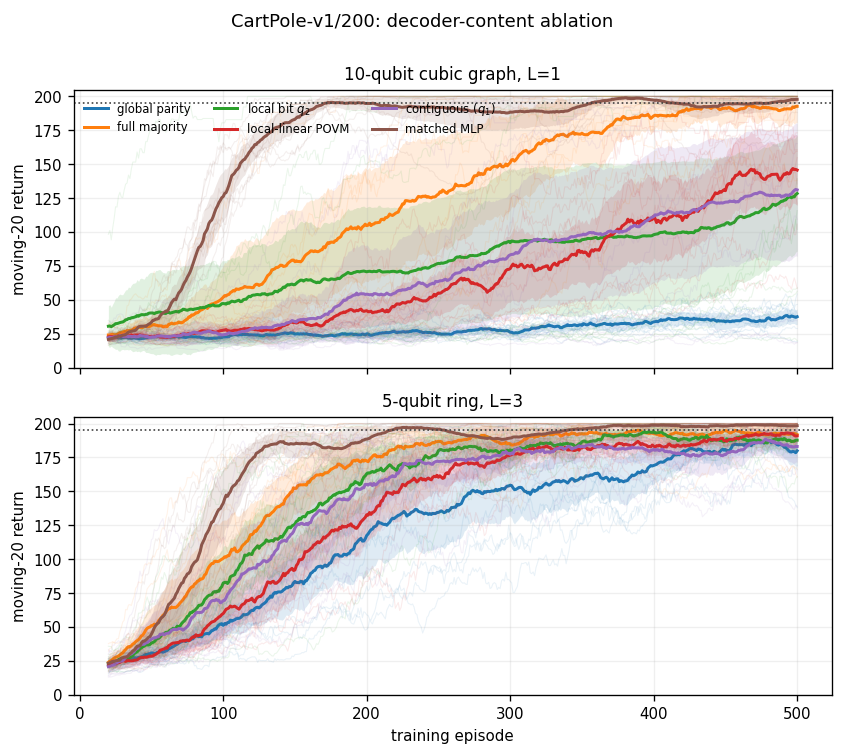

In [12]:
LABELS = {
    "parity": "global parity", "majority": "full majority",
    "local_bit_q2": "local bit $q_2$", "local_linear_povm": "local-linear POVM",
    "contiguous": "contiguous ($q_1$)", "classical_mlp": "matched MLP",
}
COLORS = dict(zip(POLICIES, plt.get_cmap("tab10").colors[:len(POLICIES)]))

fig, axes = plt.subplots(2, 1, figsize=(7.1, 6.2), sharex=True, sharey=True)
window = 20
for ax, architecture in zip(axes, ARCHITECTURES):
    for policy in POLICIES:
        subset = training_df[(training_df.architecture == architecture) &
                             (training_df.policy == policy)]
        curves = []
        for seed in SEEDS:
            values = subset[subset.seed == seed].sort_values("episode")["return"].to_numpy()
            moving = np.convolve(values, np.ones(window)/window, mode="valid")
            curves.append(moving)
            ax.plot(np.arange(window, N_EPISODES+1), moving,
                    color=COLORS[policy], alpha=0.09, linewidth=0.65)
        curves = np.asarray(curves); mean = curves.mean(axis=0)
        ci = 1.96 * curves.std(axis=0, ddof=1) / np.sqrt(len(SEEDS))
        x = np.arange(window, N_EPISODES+1)
        ax.plot(x, mean, color=COLORS[policy], label=LABELS[policy])
        ax.fill_between(x, np.clip(mean-ci, 0, 200), np.clip(mean+ci, 0, 200),
                        color=COLORS[policy], alpha=0.14, linewidth=0)
    ax.axhline(195, color="0.25", linestyle=":", linewidth=1)
    ax.set_title(ARCHITECTURES[architecture]["label"])
    ax.set_ylabel("moving-20 return")
    ax.set_ylim(0, 205); ax.grid(alpha=0.2)
axes[-1].set_xlabel("training episode")
axes[0].legend(ncol=3, frameon=False, loc="upper left")
fig.suptitle("CartPole-v1/200: decoder-content ablation", y=1.005)
fig.tight_layout()
for suffix in ("png", "pdf"):
    fig.savefig(FIGURES_DIR / f"decoder_ablation_learning_curves.{suffix}",
                dpi=300, bbox_inches="tight")
plt.show()

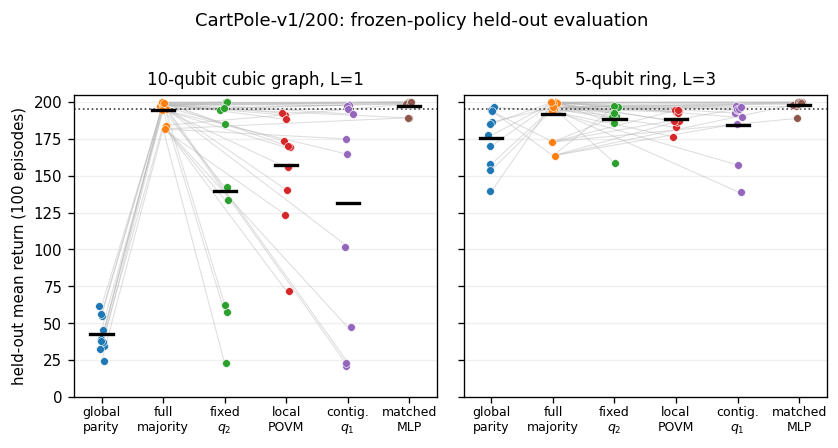

In [13]:
fig, axes = plt.subplots(1, 2, figsize=(7.1, 3.6), sharey=True)
rng_plot = np.random.default_rng(123)
heldout_labels = {
    "parity": "global\nparity",
    "majority": "full\nmajority",
    "local_bit_q2": "fixed\n$q_2$",
    "local_linear_povm": "local\nPOVM",
    "contiguous": "contig.\n$q_1$",
    "classical_mlp": "matched\nMLP",
}
for ax, architecture in zip(axes, ARCHITECTURES):
    pivot = metadata_df[metadata_df.architecture == architecture].pivot(
        index="seed", columns="policy", values="evaluation_mean"
    ).loc[list(SEEDS), list(POLICIES)]
    for column, policy in enumerate(POLICIES):
        x = column + rng_plot.normal(0, 0.035, len(SEEDS))
        ax.scatter(x, pivot[policy], s=22, color=COLORS[policy], zorder=3,
                   edgecolor="white", linewidth=0.35)
        if policy != "majority":
            for seed in SEEDS:
                ax.plot([1, column], [pivot.loc[seed, "majority"], pivot.loc[seed, policy]],
                        color="0.72", alpha=0.45, linewidth=0.65, zorder=1)
        ax.plot([column-0.18, column+0.18], [pivot[policy].mean()]*2,
                color="black", linewidth=2.0, zorder=4)
    ax.axhline(195, color="0.25", linestyle=":", linewidth=1)
    ax.set_xticks(range(len(POLICIES)), [heldout_labels[p] for p in POLICIES],
                  rotation=0)
    ax.tick_params(axis="x", labelsize=7.5, pad=2)
    ax.set_title(ARCHITECTURES[architecture]["label"]); ax.grid(axis="y", alpha=0.2)
axes[0].set_ylabel("held-out mean return (100 episodes)")
axes[0].set_ylim(0, 205)
fig.suptitle("CartPole-v1/200: frozen-policy held-out evaluation", y=1.02)
fig.tight_layout()
for suffix in ("png", "pdf"):
    fig.savefig(FIGURES_DIR / f"heldout_evaluation_paired.{suffix}",
                dpi=300, bbox_inches="tight")
plt.show()

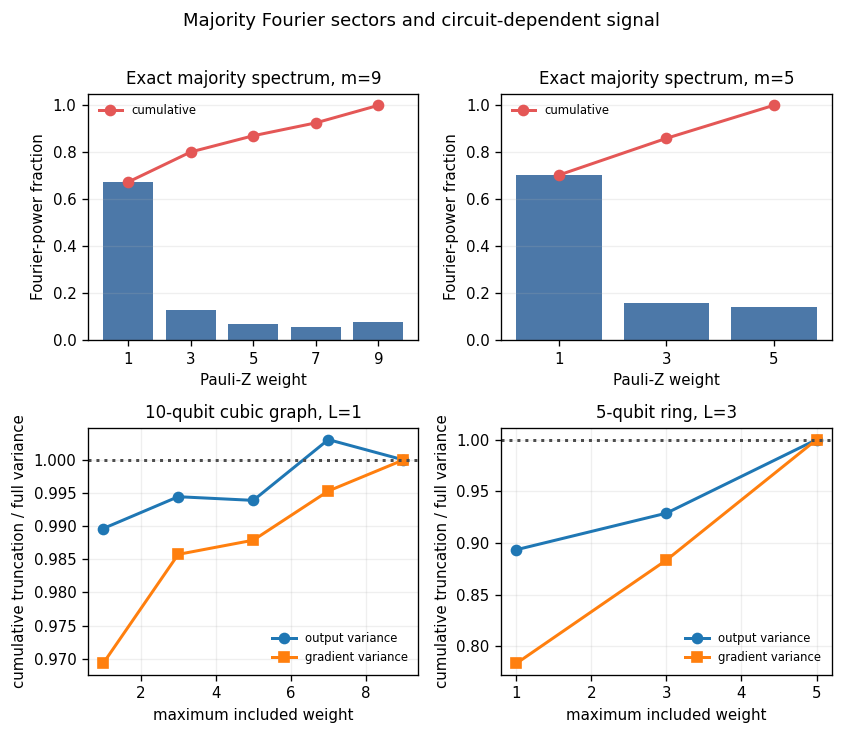

In [14]:
fig, axes = plt.subplots(2, 2, figsize=(7.1, 6.0))
for column, (m, architecture) in enumerate(((9, "expander_10_L1"), (5, "ring_5_L3"))):
    table = fourier_tables[m]
    ax = axes[0, column]
    ax.bar(table.weight.astype(str), table.power_fraction, color="#4C78A8")
    ax.plot(range(len(table)), table.cumulative_power_fraction, color="#E45756",
            marker="o", label="cumulative")
    ax.set_ylim(0, 1.05); ax.set_title(f"Exact majority spectrum, m={m}")
    ax.set_xlabel("Pauli-Z weight"); ax.set_ylabel("Fourier-power fraction")
    ax.legend(frameon=False); ax.grid(axis="y", alpha=0.2)

    ax = axes[1, column]
    subset = spectral_df[spectral_df.architecture == architecture]
    for quantity, marker in (("output_variance", "o"), ("gradient_variance", "s")):
        rows = subset[subset.quantity == quantity].sort_values("max_weight")
        ax.plot(rows.max_weight, rows.truncation_variance_ratio, marker=marker,
                label=quantity.replace("_", " "))
    ax.axhline(1, color="0.3", linestyle=":")
    ax.set_title(ARCHITECTURES[architecture]["label"])
    ax.set_xlabel("maximum included weight")
    ax.set_ylabel("cumulative truncation / full variance")
    ax.grid(alpha=0.2); ax.legend(frameon=False)
fig.suptitle("Majority Fourier sectors and circuit-dependent signal", y=1.01)
fig.tight_layout()
for suffix in ("png", "pdf"):
    fig.savefig(FIGURES_DIR / f"majority_spectral_sector_contributions.{suffix}",
                dpi=300, bbox_inches="tight")
plt.show()

In [15]:
import importlib.metadata as metadata

def package_version(name):
    try: return metadata.version(name)
    except metadata.PackageNotFoundError: return None

config = {
    "environment_label": "CartPole-v1/200",
    "gymnasium_environment_id": "CartPole-v1",
    "trainer_side_step_cap": MAX_STEPS,
    "training_episodes": N_EPISODES,
    "heldout_evaluation_episodes_per_seed": N_EVAL_EPISODES,
    "seeds": list(SEEDS), "policies": list(POLICIES),
    "fixed_local_decoder": "second measured qubit q2 (zero-based wire 1)",
    "contiguous_binary_equivalence": "leading measured qubit q1 (zero-based wire 0)",
    "training": TRAINING, "architectures": ARCHITECTURES,
    "spectral_initializations": N_SPECTRAL_INITIALIZATIONS,
    "spectral_states": len(SPECTRAL_STATES),
    "spectral_interpretation": "exact Walsh sectors; covariance-aware circuit attribution; truncations are not policies",
    "parallel_jobs": N_JOBS,
    "parallelism_benchmark": "four workers produced no new checkpoint after about 11 minutes versus a 3.5-minute first completion with two workers; production retained two workers",
    "batched_evaluation_check": "unsupported by the installed PennyLane TorchLayer for a single SparseHamiltonian expectation; retained exact 100-episode sequential evaluation",
}
(RESULTS_DIR / "experiment_config.json").write_text(json.dumps(config, indent=2))

software = {
    "python": sys.version, "platform": platform.platform(),
    "git_commit": subprocess.check_output(["git", "rev-parse", "HEAD"], cwd=ROOT, text=True).strip(),
    "git_branch": subprocess.check_output(["git", "branch", "--show-current"], cwd=ROOT, text=True).strip(),
    "packages": {name: package_version(name) for name in
                 ("qasp", "pennylane", "pennylane-lightning", "torch",
                  "gymnasium", "numpy", "pandas", "scipy", "matplotlib", "joblib")},
}
(RESULTS_DIR / "software_metadata.json").write_text(json.dumps(software, indent=2))

files = []
for path in sorted(RESULTS_DIR.rglob("*")):
    if path.is_file() and path.name != "manifest.json":
        files.append({
            "path": str(path.relative_to(RESULTS_DIR)), "bytes": path.stat().st_size,
            "sha256": hashlib.sha256(path.read_bytes()).hexdigest(),
        })
manifest = {
    "completed": True, "n_expected_runs": len(ARCHITECTURES)*len(POLICIES)*len(SEEDS),
    "n_completed_runs": len(metadata_df), "training_rows": len(training_df),
    "evaluation_rows": len(evaluation_df),
    "all_cells_executed_from_clean_kernel": True,
    "files": files,
}
(RESULTS_DIR / "manifest.json").write_text(json.dumps(manifest, indent=2))

print("Completed runs:", len(metadata_df))
print("Total quantum training forward calls:",
      int(metadata_df.training_forward_circuit_calls.sum()))
print("Total quantum evaluation forward calls:",
      int(metadata_df.evaluation_forward_circuit_calls.sum()))
print("Results:", RESULTS_DIR)
print("\nPrincipal means:")
display(summary_df[["architecture", "policy", "mean_training_final_50",
                    "mean_heldout_evaluation", "heldout_solved_seed_fraction"]])

Completed runs: 120
Total quantum training forward calls: 5351026
Total quantum evaluation forward calls: 1594150
Results: ./tests/results/majority_local_sector_ablation

Principal means:


,architecture,policy,mean_training_final_50,mean_heldout_evaluation,heldout_solved_seed_fraction
0,expander_10_L1,parity,36.634,42.348,0.0
1,expander_10_L1,majority,191.880,194.687,0.6
2,expander_10_L1,local_bit_q2,120.926,139.464,0.3
3,expander_10_L1,local_linear_povm,144.774,157.553,0.0
4,expander_10_L1,contiguous,128.924,131.490,0.3
5,expander_10_L1,classical_mlp,196.114,197.348,0.8
6,ring_5_L3,parity,183.304,175.440,0.1
7,ring_5_L3,majority,192.006,191.675,0.7
8,ring_5_L3,local_bit_q2,187.776,188.420,0.2
9,ring_5_L3,local_linear_povm,191.678,188.756,0.0


## Interpretation guardrails

- The held-out stage is the primary generalization check; final-50 training
  return is reported separately.
- Paired intervals resample matched seeds and retain all seed-level points.
- The local-linear POVM is a realizable randomized decoder, not majority with
  its higher weights simply deleted: positivity forces a smaller singleton
  coefficient.
- Spectral truncations diagnose where majority's observable and gradient
  signals reside. They are not deployed as policies unless positivity is
  separately established.
- For binary actions, QASP contiguous is a deterministic local (q_1) rule;
  the explicit local-bit ablation intentionally uses (q_2).